# 3D Image analysis

This notebook shows an example of 3D image analysis using the `pyvane` library.  

## Data preparation

Imports, load example image, segment and obtain the skeleton.

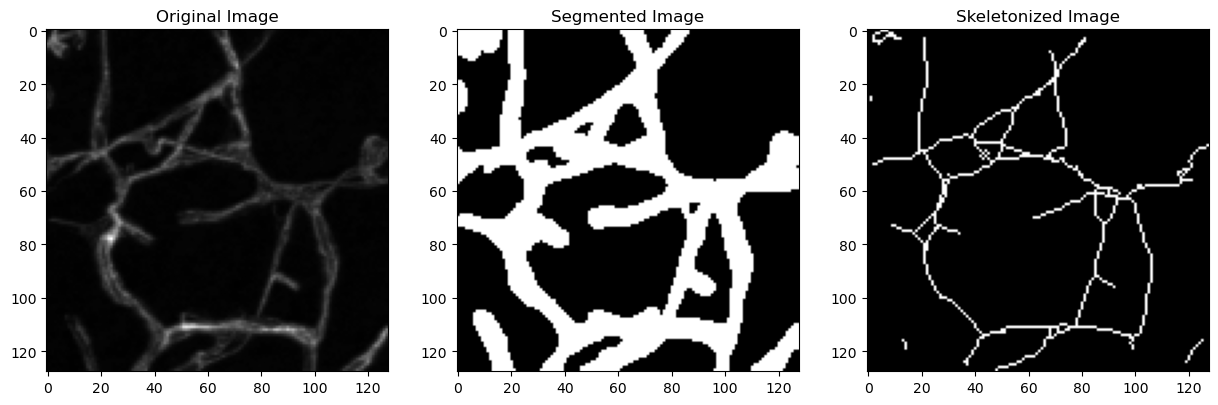

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import tifffile

from pyvane.graph.creation import create_graph, create_graph_with_mapping
from pyvane.segmentation import local_threshold
from pyvane.skeletonization import lee
from pyvane.util.misc import graph_to_img

file_path = "../data/3d_image.tiff"
img = tifffile.imread(file_path)

bin_img = local_threshold.vessel_segmentation(
    img, threshold=1, sigma=1, radius=40, comp_size=10, hole_size=10)

bin_img_pad = np.pad(bin_img, 1, mode="constant", constant_values=1)
skel_img = lee.skeletonize(bin_img)


fig, axs = plt.subplots(1, 3, figsize=(15, 5))
axs[0].imshow(img.max(axis=0), cmap="gray")
axs[0].set_title("Original Image")
axs[1].imshow(bin_img.max(axis=0), cmap="gray")
axs[1].set_title("Segmented Image")
axs[2].imshow(skel_img.max(axis=0), cmap="gray")
axs[2].set_title("Skeletonized Image")
plt.show()

## Graph creation

The function `create_graph` extracts a graph from a binary skeleton image. The function also needs the original binary image to run some heuristics to simplify the graph.

The parameter `length_threshold` sets the scale for artifacts to be removed from the graph. Leaf branches, multiple edges between nodes and self-loops smaller than length_threshold are removed from the graph. An example showing the full set of parameters for graph creation is shown at the end of this notebook.

Text(0.5, 1.0, 'Graph Visualization')

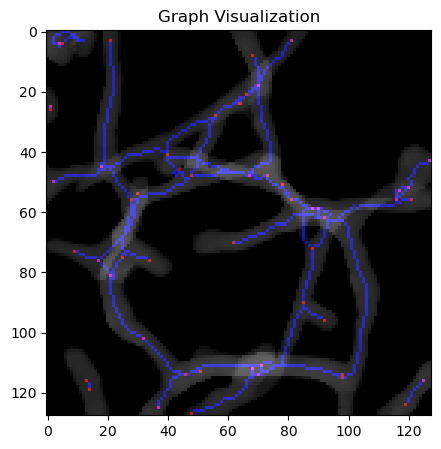

In [2]:
graph = create_graph(skel_img, bin_img, length_threshold=5) 

graph_img = graph_to_img(
    graph, 
    img_shape=img.shape, 
    node_color=(255, 0, 0),
    node_pixels_color=(0, 0, 0), 
    edge_color=(0, 0, 255)
    )

plt.figure(figsize=(5, 5))
plt.imshow(graph_img.max(axis=0))
plt.imshow(bin_img.sum(axis=0), cmap="gray", alpha=0.4)
plt.title("Graph Visualization")

## Assignment of vessel segments to graph nodes and edges

The function `create_graph_with_mapping` returns a labeled array where each foreground pixel maps to the closest pixel in the centerline of a vessel segment. Please see the tutorial notebook ``1 - Graph creation.ipynb`` for more details.

In [3]:
graph, labeled_image, id_cl_map = create_graph_with_mapping(skel_img, bin_img, length_threshold=10)

## Extraction of vessel properties

Some built in PyVaNe properties:

In [4]:
from pyvane.graph.util import construct_attribute_volume
from pyvane.metrics import metrics

print(
    "Vessel density:", metrics.vessel_density(graph, img.shape),
    "\nBranch point density:", metrics.branch_point_density(graph, img.shape),
    "\nTortuosity:", metrics.tortuosity(graph, scale=5)
)

Vessel density: 0.0012655235434765363 
Branch point density: 2.3193359375e-05 
Tortuosity: 0.31536864450889346


Assignment of a radius value to each centerline pixel. Each edge will have a `radii` attribute with the same size as the respective `path` coordinates.

In [5]:
bin_img = labeled_image > 0
metrics.assign_centerline_radii(graph, bin_img)

An image can be constructed from a graph, the respective labeled volume, the id mapping and specific edge attribute:

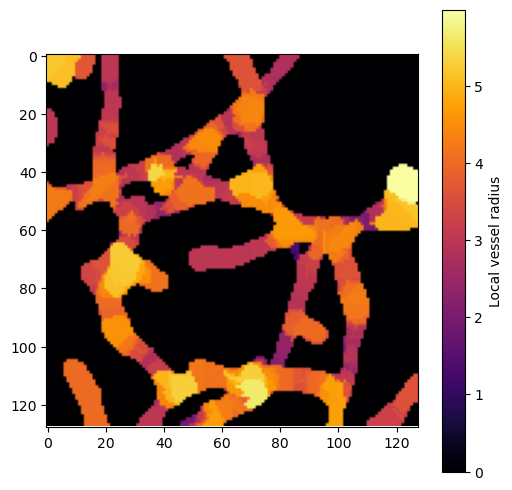

In [6]:
attribute_volume = construct_attribute_volume(
    graph, labeled_image, id_cl_map=id_cl_map, edge_attr="radii")

attribute_volume[attribute_volume != attribute_volume] = 0
plt.figure(figsize=(6, 6))
plt.imshow(attribute_volume.max(axis=0), cmap="inferno")
plt.colorbar(label="Local vessel radius")

## Calculate the mean radius of each vessel segment

In [7]:
for u, v, key, data in graph.edges(keys=True, data=True):
    radii = data["radii"]
    # Get outer path
    outer_start, outer_end = data["trim_amount"]
    radii = radii[outer_start:len(radii)-outer_end]

    if len(radii) > 0:
        mean_radius = np.mean(radii).item()
    else:
        # Assign node radius for robustness
        mean_radius = (graph.nodes[u]["radius"] + graph.nodes[v]["radius"]) / 2.0
    data["mean_radius"] = mean_radius

We can plot the histogram of values:

(array([2., 1., 1., 1., 2., 3., 3., 3., 5., 4., 4., 3., 2., 1., 1., 1., 1.,
        2., 1., 2.]),
 array([2.11560743, 2.24038019, 2.36515294, 2.4899257 , 2.61469846,
        2.73947121, 2.86424397, 2.98901673, 3.11378949, 3.23856224,
        3.363335  , 3.48810776, 3.61288051, 3.73765327, 3.86242603,
        3.98719878, 4.11197154, 4.2367443 , 4.36151706, 4.48628981,
        4.61106257]),
 <BarContainer object of 20 artists>)

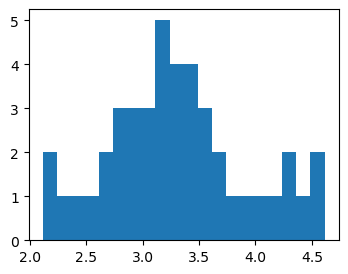

In [8]:
radii = [edge[3]["mean_radius"] for edge in graph.edges(keys=True, data=True)]
plt.hist(radii, 20)